In [1]:
%% MIT 18.03 Lecture 34: Complex Eigenvalues, Defective & Complete Repeated Roots
% Description: Simulates the three canonical 2x2 state-space topologies via Control System Toolbox:
%              1) Complex Eigenvalues: A1 = [1, 2; -2, 1] -> Clockwise Outward Spiral (lambda = 1 +/- 2i).
%              2) Defective Repeated Root: A2 = [-2, 1; -1, 0] -> Improper Node (lambda = -1, v = [1;1], w = [0;1]).
%              3) Complete Repeated Root: A3 = [2, 0; 0, 2] -> Star Node (every vector is an eigenvector).
%
% % Required Toolboxes:
% %   - Control System Toolbox (ss, initial, pole, canon).
%
% % MBD Concept Mapping: Demonstrates Real Modal Form for complex conjugate poles,
% %                      Jordan Block secular terms t*e^{\lambda t} for defective critical damping,
% %                      and geometric multiplicity in complete isotropic systems.


clear; clc; close all;


%% =========================================================================
%% Part 1: Complex Eigenvalues A1 = [1, 2; -2, 1] (Lecture Section [2])
%% =========================================================================
A1 = [ 1,  2;
      -2,  1];
sys_complex = ss(A1, zeros(2,1), eye(2), zeros(2,1));
poles_1 = pole(sys_complex);


fprintf('=== MIT 18.03 Lecture 34 Eigenvalue Topologies ===\n');

=== MIT 18.03 Lecture 34 Eigenvalue Topologies ===

In [2]:
fprintf('1) Complex Matrix A1 = [1, 2; -2, 1]\n');

1) Complex Matrix A1 = [1, 2; -2, 1]

In [3]:
fprintf('   tr(A1) = %.1f, det(A1) = %.1f  -->  p(lambda) = lambda^2 - 2*lambda + 5\n', trace(A1), det(A1));

   tr(A1) = 2.0, det(A1) = 5.0  -->  p(lambda) = lambda^2 - 2*lambda + 5

In [4]:
fprintf('   Eigenvalues: %+.2f %+.2fi,  %+.2f %+.2fi (Unstable Clockwise Spiral)\n\n', ...
        real(poles_1(1)), imag(poles_1(1)), real(poles_1(2)), imag(poles_1(2)));

   Eigenvalues: +1.00 +2.00i,  +1.00 -2.00i (Unstable Clockwise Spiral)

In [5]:


% Simulate basis solutions u1(0) = [1; 0] and u2(0) = [0; 1] via 'initial'
t1 = linspace(0, 1.8, 500);
[u1_sim, ~] = initial(sys_complex, [1; 0], t1);
[u2_sim, ~] = initial(sys_complex, [0; 1], t1);


% Analytical real and imaginary parts from lecture:
u1_exact = [exp(t1).*cos(2*t1); -exp(t1).*sin(2*t1)];
u2_exact = [exp(t1).*sin(2*t1);  exp(t1).*cos(2*t1)];


%% =========================================================================
%% Part 2: Defective Repeated Root A2 = [-2, 1; -1, 0] (Lecture Section [3])
%% =========================================================================
A2 = [-2,  1;
      -1,  0];
sys_defective = ss(A2, zeros(2,1), eye(2), zeros(2,1));
poles_2 = pole(sys_defective);
lambda_rep = poles_2(1); % -1


% Eigenvector v = [1; 1] and Generalized Eigenvector w = [0; 1] satisfying (A2 - lambda*I)*w = v
v_def = [1; 1];
w_def = [0; 1];
check_gen = (A2 - lambda_rep * eye(2)) * w_def; % Must equal [1; 1]


fprintf('2) Defective Matrix A2 = [-2, 1; -1, 0]\n');

2) Defective Matrix A2 = [-2, 1; -1, 0]

In [6]:
fprintf('   tr(A2) = %.1f, det(A2) = %.1f  -->  p(lambda) = (lambda + 1)^2\n', trace(A2), det(A2));

   tr(A2) = -2.0, det(A2) = 1.0  -->  p(lambda) = (lambda + 1)^2

In [7]:
fprintf('   Repeated Eigenvalue     : lambda = %.2f (Geometric Multiplicity = 1)\n', lambda_rep);

   Repeated Eigenvalue     : lambda = -1.00 (Geometric Multiplicity = 1)

In [8]:
fprintf('   Single Eigenvector v    : [%d; %d]\n', v_def(1), v_def(2));

   Single Eigenvector v    : [1; 1]

In [9]:
fprintf('   Generalized Vector w    : [%d; %d], Check (A - lambda*I)w = [%d; %d]\n\n', ...
        w_def(1), w_def(2), round(check_gen(1)), round(check_gen(2)));

   Generalized Vector w    : [0; 1], Check (A - lambda*I)w = [1; 1]

In [10]:


t2 = linspace(0, 4.5, 500);
[u_def_sim, ~] = initial(sys_defective, w_def, t2); % Starting at u2(0) = w = [0; 1]
u_def_exact    = [exp(-t2).*t2; exp(-t2).*(t2 + 1)];


%% =========================================================================
%% Part 3: Complete Repeated Root A3 = [2, 0; 0, 2] (Lecture Section [4])
%% =========================================================================
A3 = [2, 0;
      0, 2];
sys_complete = ss(A3, zeros(2,1), eye(2), zeros(2,1));
fprintf('3) Complete Matrix A3 = [2, 0; 0, 2]\n');

3) Complete Matrix A3 = [2, 0; 0, 2]

In [11]:
fprintf('   Repeated Eigenvalue     : lambda = +2.00 (Geometric Multiplicity = 2)\n');

   Repeated Eigenvalue     : lambda = +2.00 (Geometric Multiplicity = 2)

In [12]:
fprintf('   Every nonzero vector in R^2 is an eigenvector (Star Node)!\n');

   Every nonzero vector in R^2 is an eigenvector (Star Node)!

In [13]:
fprintf('==================================================\n');


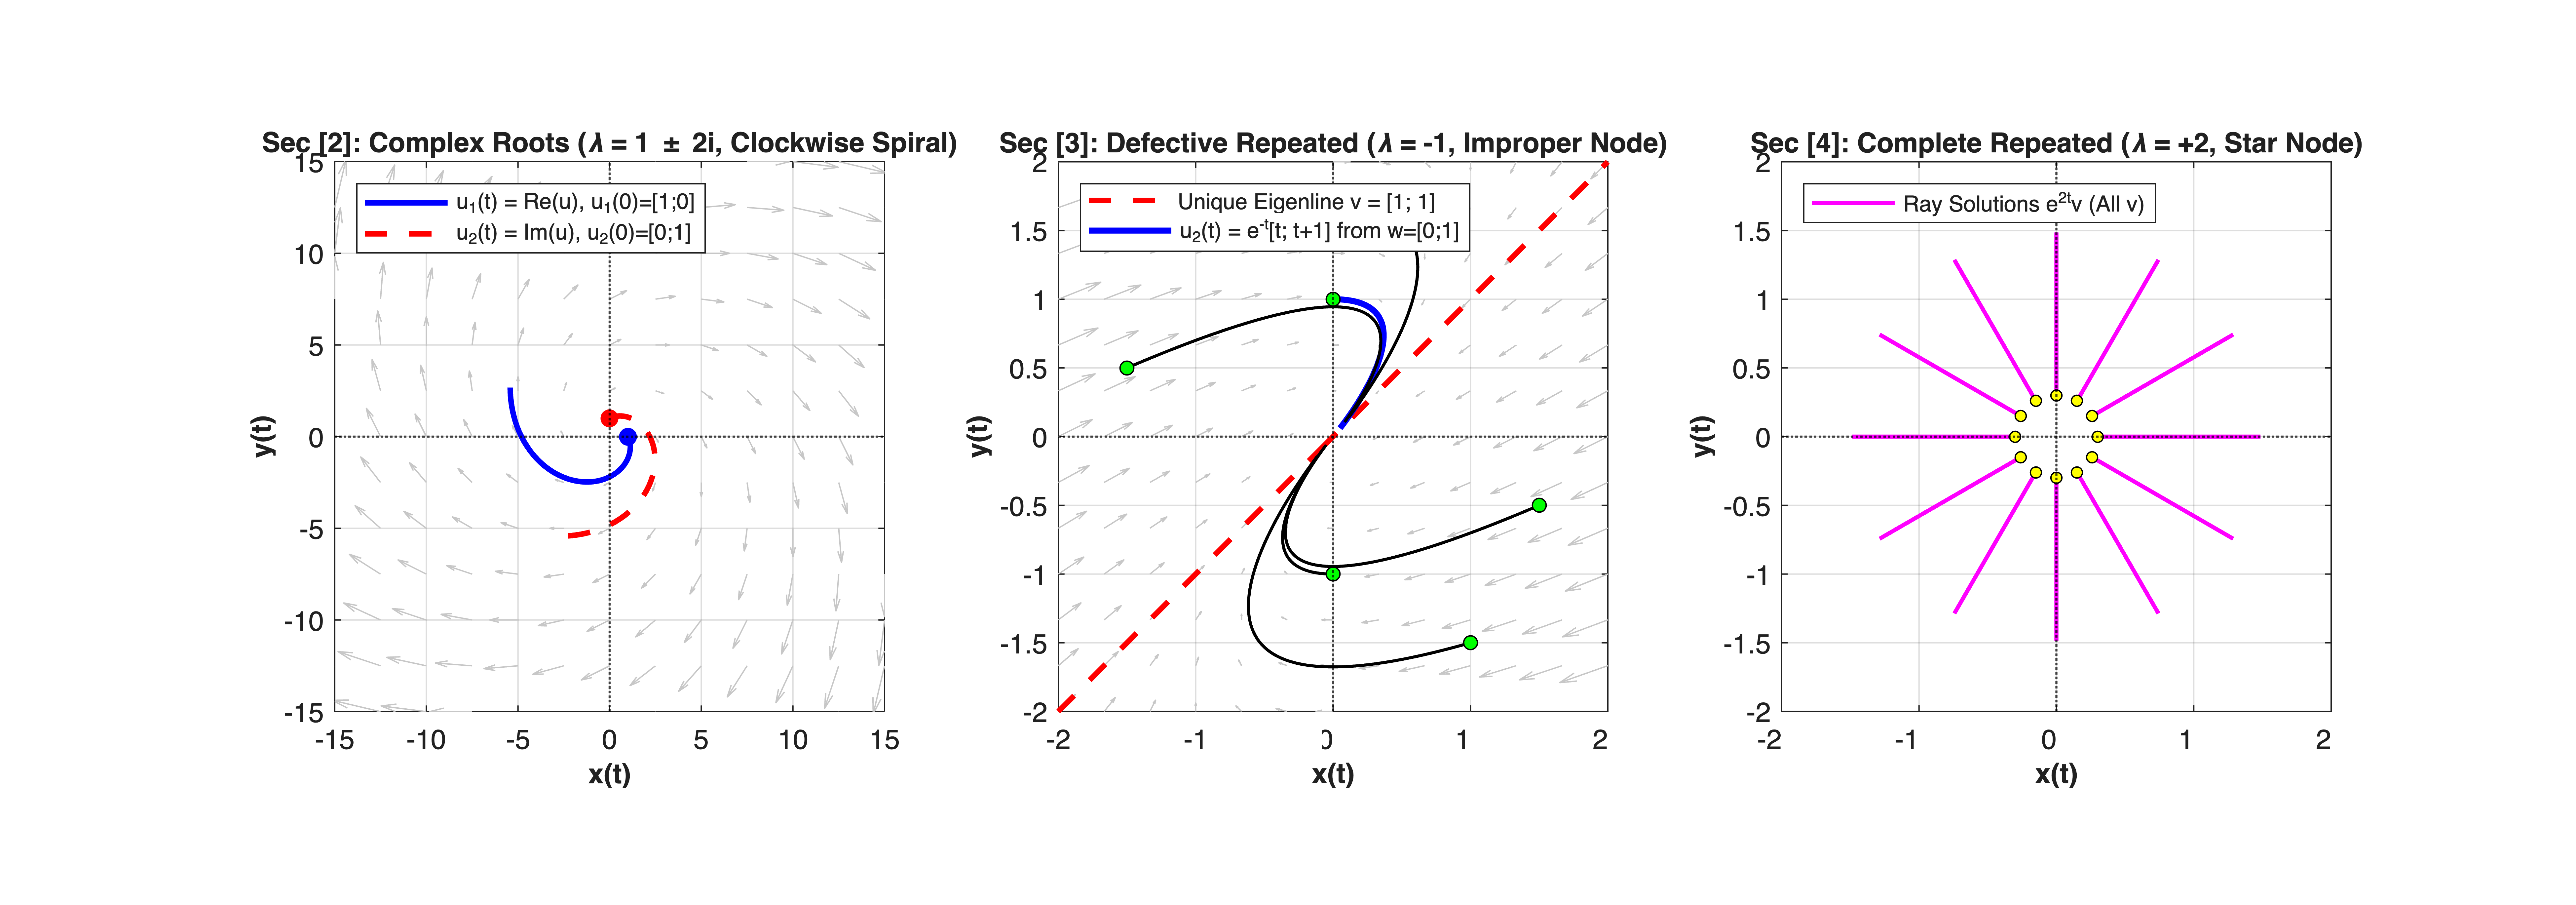

In [14]:


%% =========================================================================
%% Part 4: Three-Panel Phase Portrait Comparison
%% =========================================================================
figure('Color', [1 1 1], 'Position', [60, 60, 1280, 450]);


% Subplot 1: Complex Eigenvalues (Clockwise Spiral)
subplot(1, 3, 1);
hold on; grid on; box on;
xline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');
yline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');


[X1, Y1] = meshgrid(linspace(-15, 15, 13));
quiver(X1, Y1, A1(1,1)*X1 + A1(1,2)*Y1, A1(2,1)*X1 + A1(2,2)*Y1, ...
       'Color', [0.78 0.78 0.78], 'HandleVisibility', 'off');


plot(u1_sim(:, 1), u1_sim(:, 2), 'b-', 'LineWidth', 2.0, ...
     'DisplayName', 'u_1(t) = Re(u), u_1(0)=[1;0]');
plot(u2_sim(:, 1), u2_sim(:, 2), 'r--', 'LineWidth', 2.0, ...
     'DisplayName', 'u_2(t) = Im(u), u_2(0)=[0;1]');
plot(1, 0, 'bo', 'MarkerFaceColor', 'b', 'MarkerSize', 6, 'HandleVisibility', 'off');
plot(0, 1, 'ro', 'MarkerFaceColor', 'r', 'MarkerSize', 6, 'HandleVisibility', 'off');


xlabel('x(t)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('y(t)', 'FontSize', 10, 'FontWeight', 'bold');
title('Sec [2]: Complex Roots (\lambda = 1 \pm 2i, Clockwise Spiral)', ...
      'FontSize', 10, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8);
axis equal; xlim([-15, 15]); ylim([-15, 15]);


% Subplot 2: Defective Repeated Root (Improper Node with Single Eigenline)
subplot(1, 3, 2);
hold on; grid on; box on;
xline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');
yline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');


[X2, Y2] = meshgrid(linspace(-2, 2, 13));
quiver(X2, Y2, A2(1,1)*X2 + A2(1,2)*Y2, A2(2,1)*X2 + A2(2,2)*Y2, ...
       'Color', [0.78 0.78 0.78], 'HandleVisibility', 'off');


% Plot the ONLY eigenline: span([1; 1])
s_line = linspace(-2, 2, 100);
plot(s_line * v_def(1), s_line * v_def(2), 'r--', 'LineWidth', 2.0, ...
     'DisplayName', 'Unique Eigenline v = [1; 1]');


% Plot family of defective trajectories curving into the eigenline
ic_def = [0, 1;  0, -1;  -1.5, 0.5;  1.5, -0.5;  -1, 1.5;  1, -1.5]';
for k = 1:size(ic_def, 2)
    [u_tr, ~] = initial(sys_defective, ic_def(:, k), t2);
    if k == 1
        plot(u_tr(:, 1), u_tr(:, 2), 'b-', 'LineWidth', 2.2, ...
             'DisplayName', 'u_2(t) = e^{-t}[t; t+1] from w=[0;1]');
    else
        plot(u_tr(:, 1), u_tr(:, 2), 'k-', 'LineWidth', 1.1, 'HandleVisibility', 'off');
    end
    plot(ic_def(1, k), ic_def(2, k), 'ko', 'MarkerFaceColor', 'g', ...
         'MarkerSize', 5, 'HandleVisibility', 'off');
end


xlabel('x(t)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('y(t)', 'FontSize', 10, 'FontWeight', 'bold');
title('Sec [3]: Defective Repeated (\lambda = -1, Improper Node)', ...
      'FontSize', 10, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8);
axis equal; xlim([-2, 2]); ylim([-2, 2]);


% Subplot 3: Complete Repeated Root (Star Node - All Rays)
subplot(1, 3, 3);
hold on; grid on; box on;
xline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');
yline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');


t3 = linspace(0, 0.8, 100);
angles = linspace(0, 2*pi, 13);
for ang = angles(1:end-1)
    u0_ray = 0.3 * [cos(ang); sin(ang)];
    [u_star, ~] = initial(sys_complete, u0_ray, t3);
    plot(u_star(:, 1), u_star(:, 2), 'm-', 'LineWidth', 1.5, 'HandleVisibility', 'off');
    plot(u0_ray(1), u0_ray(2), 'ko', 'MarkerFaceColor', 'y', 'MarkerSize', 4, 'HandleVisibility', 'off');
end
plot(NaN, NaN, 'm-', 'LineWidth', 1.5, 'DisplayName', 'Ray Solutions e^{2t}v (All v)');


xlabel('x(t)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('y(t)', 'FontSize', 10, 'FontWeight', 'bold');
title('Sec [4]: Complete Repeated (\lambda = +2, Star Node)', ...
      'FontSize', 10, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8);
axis equal; xlim([-2, 2]); ylim([-2, 2]);